In [1]:
import pandas as pd
import numpy as np

# --- 1. LOAD DATA ---
print("Loading combined dataset...")
df = pd.read_csv("appended_labeledFIle.csv")
print(f"Original Shape: {df.shape}")

# --- 2. DROP THE 4 UNWANTED STRING COLUMNS ---
# Dropping the specific identifiers that break machine learning models
columns_to_drop = ['Flow ID', 'Src IP', 'Dst IP', 'Timestamp']

# Safely drop them from the dataframe
df.drop(columns=[col for col in columns_to_drop if col in df.columns], inplace=True)

print(f"Shape after dropping the identifiers: {df.shape}")

# --- 3. HANDLE INF, NAN, AND EMPTY STRINGS ---
print("\nCleaning corrupt values...")

# A. Convert completely empty strings or spaces to actual NaN
df.replace(r'^\s*$', np.nan, regex=True, inplace=True)

# B. Convert mathematical Infinity to NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# C. Count how many broken rows we have
broken_rows = df.isna().any(axis=1).sum()
print(f"Found {broken_rows} rows containing NaN or Inf.")

# D. Drop the broken rows (Safest method for a t-SNE sample)
df.dropna(inplace=True)

# --- 4. SEPARATE LABELS AND FORCE NUMERIC DATA ---
print("\nVerifying data types...")
y = df['Label']
X = df.drop(columns=['Label'])

# Force all remaining 79 feature columns to be 32-bit floats.
# If a column secretly contains a word, this line will intentionally 
# throw an error and tell you exactly which column is broken.
try:
    X = X.astype(np.float32)
    print("SUCCESS: All 79 features are perfectly numeric.")
except ValueError as e:
    print(f"\nCRITICAL ERROR: A feature column still contains text/objects!")
    print(f"Details: {e}")

print(f"\nFinal Cleaned Shape Ready for t-SNE: X={X.shape}, y={y.shape}")

Loading combined dataset...
Original Shape: (93395, 84)
Shape after dropping the identifiers: (93395, 80)

Cleaning corrupt values...
Found 0 rows containing NaN or Inf.

Verifying data types...
SUCCESS: All 79 features are perfectly numeric.

Final Cleaned Shape Ready for t-SNE: X=(93395, 79), y=(93395,)


Standardizing 79 features to uniform scale...
Scaling complete.

Initializing t-SNE Engine...
-> Utilizing all available Xeon threads (n_jobs=-1)
-> Setting random_state=42 for strict reproducibility

Starting dimensionality reduction. Watch the console for iteration updates...
[t-SNE] Computing 151 nearest neighbors...
[t-SNE] Indexed 93395 samples in 0.025s...
[t-SNE] Computed neighbors for 93395 samples in 10.087s...
[t-SNE] Computed conditional probabilities for sample 1000 / 93395
[t-SNE] Computed conditional probabilities for sample 2000 / 93395
[t-SNE] Computed conditional probabilities for sample 3000 / 93395
[t-SNE] Computed conditional probabilities for sample 4000 / 93395
[t-SNE] Computed conditional probabilities for sample 5000 / 93395
[t-SNE] Computed conditional probabilities for sample 6000 / 93395
[t-SNE] Computed conditional probabilities for sample 7000 / 93395
[t-SNE] Computed conditional probabilities for sample 8000 / 93395
[t-SNE] Computed conditional probabiliti

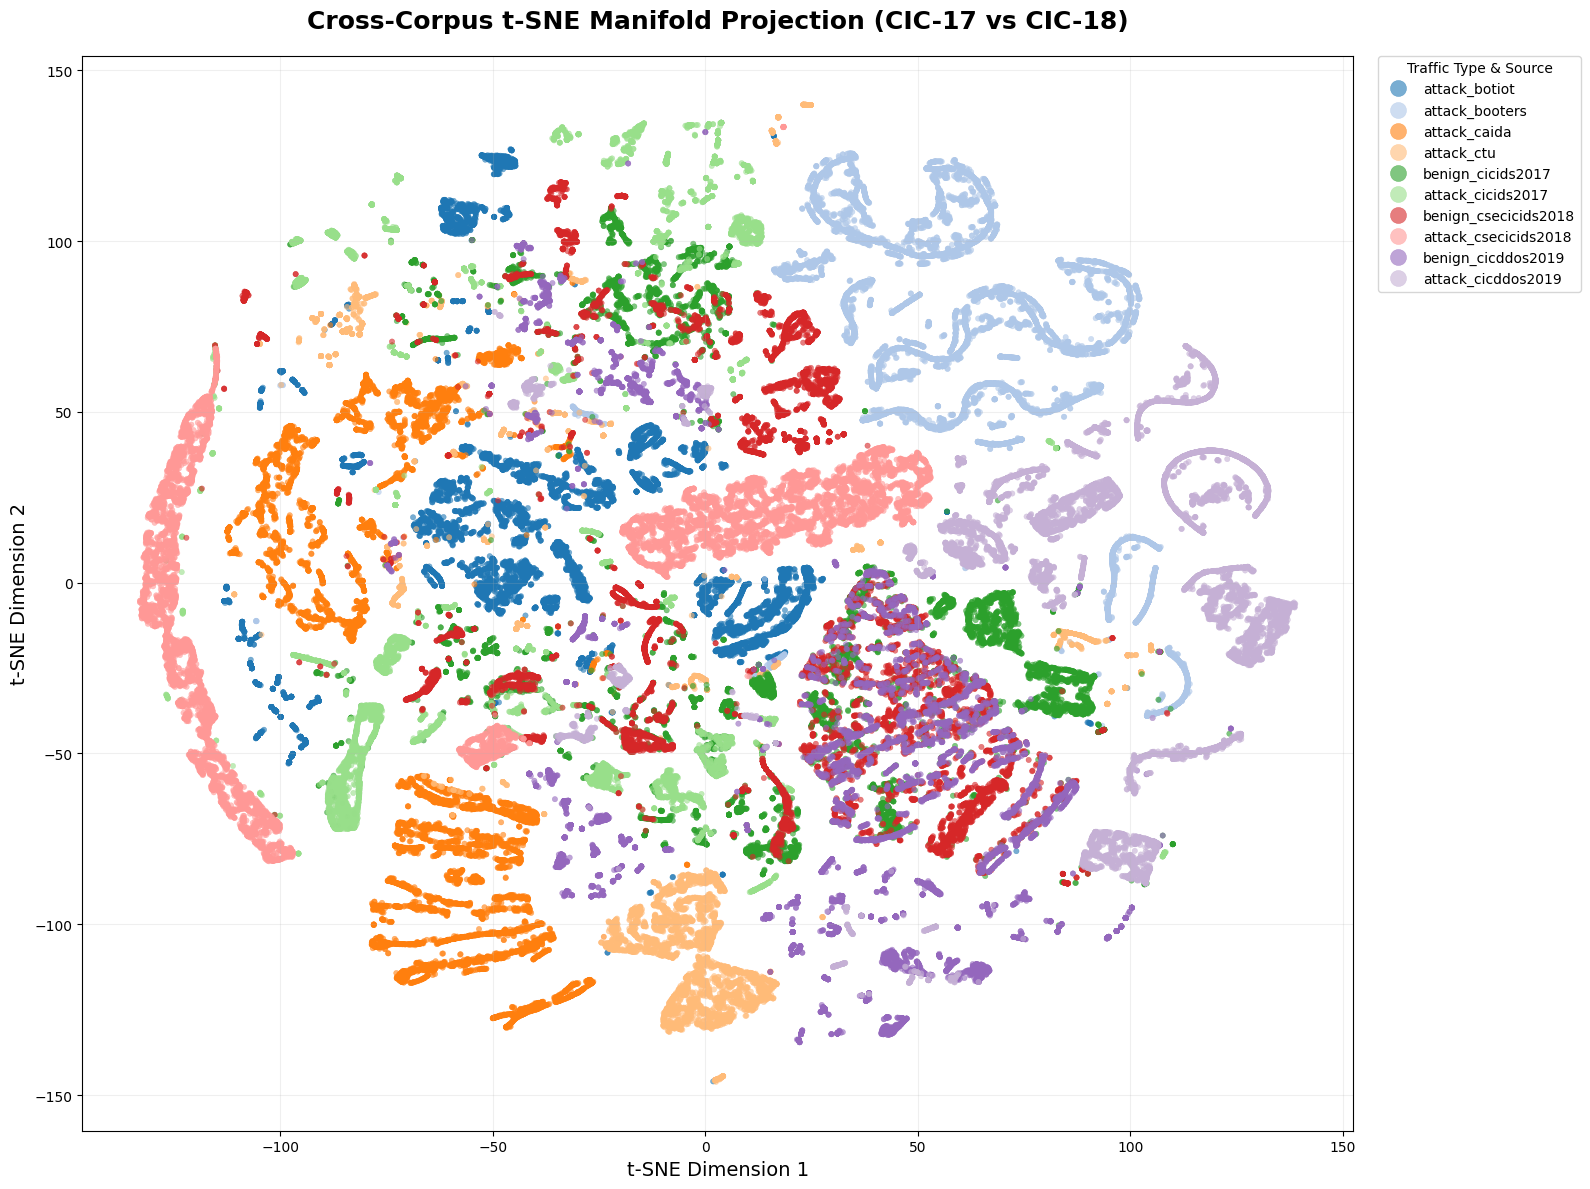

In [ ]:
import time
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# --- 1. FEATURE SCALING (CRITICAL) ---
# t-SNE measures distance. If 'Flow Bytes/s' is in the millions and 
# 'Fwd Packets/s' is a small decimal, the algorithm will fail to cluster.
print("Standardizing 79 features to uniform scale...")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaling complete.")

# --- 2. T-SNE EXECUTION ---
print("\nInitializing t-SNE Engine...")
print("-> Utilizing all available Xeon threads (n_jobs=-1)")
print("-> Setting random_state=42 for strict reproducibility")

start_time = time.time()

# Configure the engine for your specific hardware and dataset size
tsne_engine = TSNE(
    n_components=2, 
    perplexity=50,       # 50 is optimal for datasets nearing 100k rows
    max_iter=1000,       # UPDATED: Changed from  max_iter
    n_jobs=-1,           
    random_state=42, 
    verbose=1            # Prints live progress updates to your console
)

print("\nStarting dimensionality reduction. Watch the console for iteration updates...")
X_tsne = tsne_engine.fit_transform(X_scaled)

elapsed_time = (time.time() - start_time) / 60
print(f"\nSUCCESS: t-SNE completed mathematically in {elapsed_time:.2f} minutes.")

# --- 3. HIGH-RESOLUTION VISUALIZATION ---
print("\nGenerating cluster visualization...")
OUTPUT_IMAGE = "Cross_Corpus_tSNE_Clusters.png"

# Package the coordinates and labels back into a dataframe for Seaborn
df_tsne = pd.DataFrame({
    'TSNE_Dimension_1': X_tsne[:, 0],
    'TSNE_Dimension_2': X_tsne[:, 1],
    'Dataset_Label': y.values  # Ensure index alignment by using .values
})

# Create a massive, high-resolution canvas
plt.figure(figsize=(16, 12))

# Plot the dots
# Alpha=0.6 makes overlapping dots darker, revealing density
# s=15 keeps the dots small enough so they don't blur together
sns.scatterplot(
    data=df_tsne,
    x='TSNE_Dimension_1',
    y='TSNE_Dimension_2',
    hue='Dataset_Label',
    palette='tab20',     # A high-contrast color palette for multiple classes
    alpha=0.6,
    s=15,
    edgecolor=None
)

# Professional Aesthetics
plt.title("Cross-Corpus t-SNE Manifold Projection (CIC-17 vs CIC-18)", fontsize=18, fontweight='bold', pad=20)
plt.xlabel("t-SNE Dimension 1", fontsize=14)
plt.ylabel("t-SNE Dimension 2", fontsize=14)

# Move the legend safely outside the plot area
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., markerscale=3, title="Traffic Type & Source")
plt.grid(alpha=0.2)
plt.tight_layout()

# Save at 300 DPI (Publication Standard)
plt.savefig(OUTPUT_IMAGE, dpi=300, bbox_inches='tight')
print(f"Visualization saved successfully to '{OUTPUT_IMAGE}'.")

# Render it right in Jupyter
plt.show()

Applying MinMaxScaler to 79 features...
Scaling complete.

Initializing t-SNE Engine for MinMax data...

Starting dimensionality reduction. Watch the console...
[t-SNE] Computing 151 nearest neighbors...
[t-SNE] Indexed 93395 samples in 0.024s...
[t-SNE] Computed neighbors for 93395 samples in 6.447s...
[t-SNE] Computed conditional probabilities for sample 1000 / 93395
[t-SNE] Computed conditional probabilities for sample 2000 / 93395
[t-SNE] Computed conditional probabilities for sample 3000 / 93395
[t-SNE] Computed conditional probabilities for sample 4000 / 93395
[t-SNE] Computed conditional probabilities for sample 5000 / 93395
[t-SNE] Computed conditional probabilities for sample 6000 / 93395
[t-SNE] Computed conditional probabilities for sample 7000 / 93395
[t-SNE] Computed conditional probabilities for sample 8000 / 93395
[t-SNE] Computed conditional probabilities for sample 9000 / 93395
[t-SNE] Computed conditional probabilities for sample 10000 / 93395
[t-SNE] Computed conditi

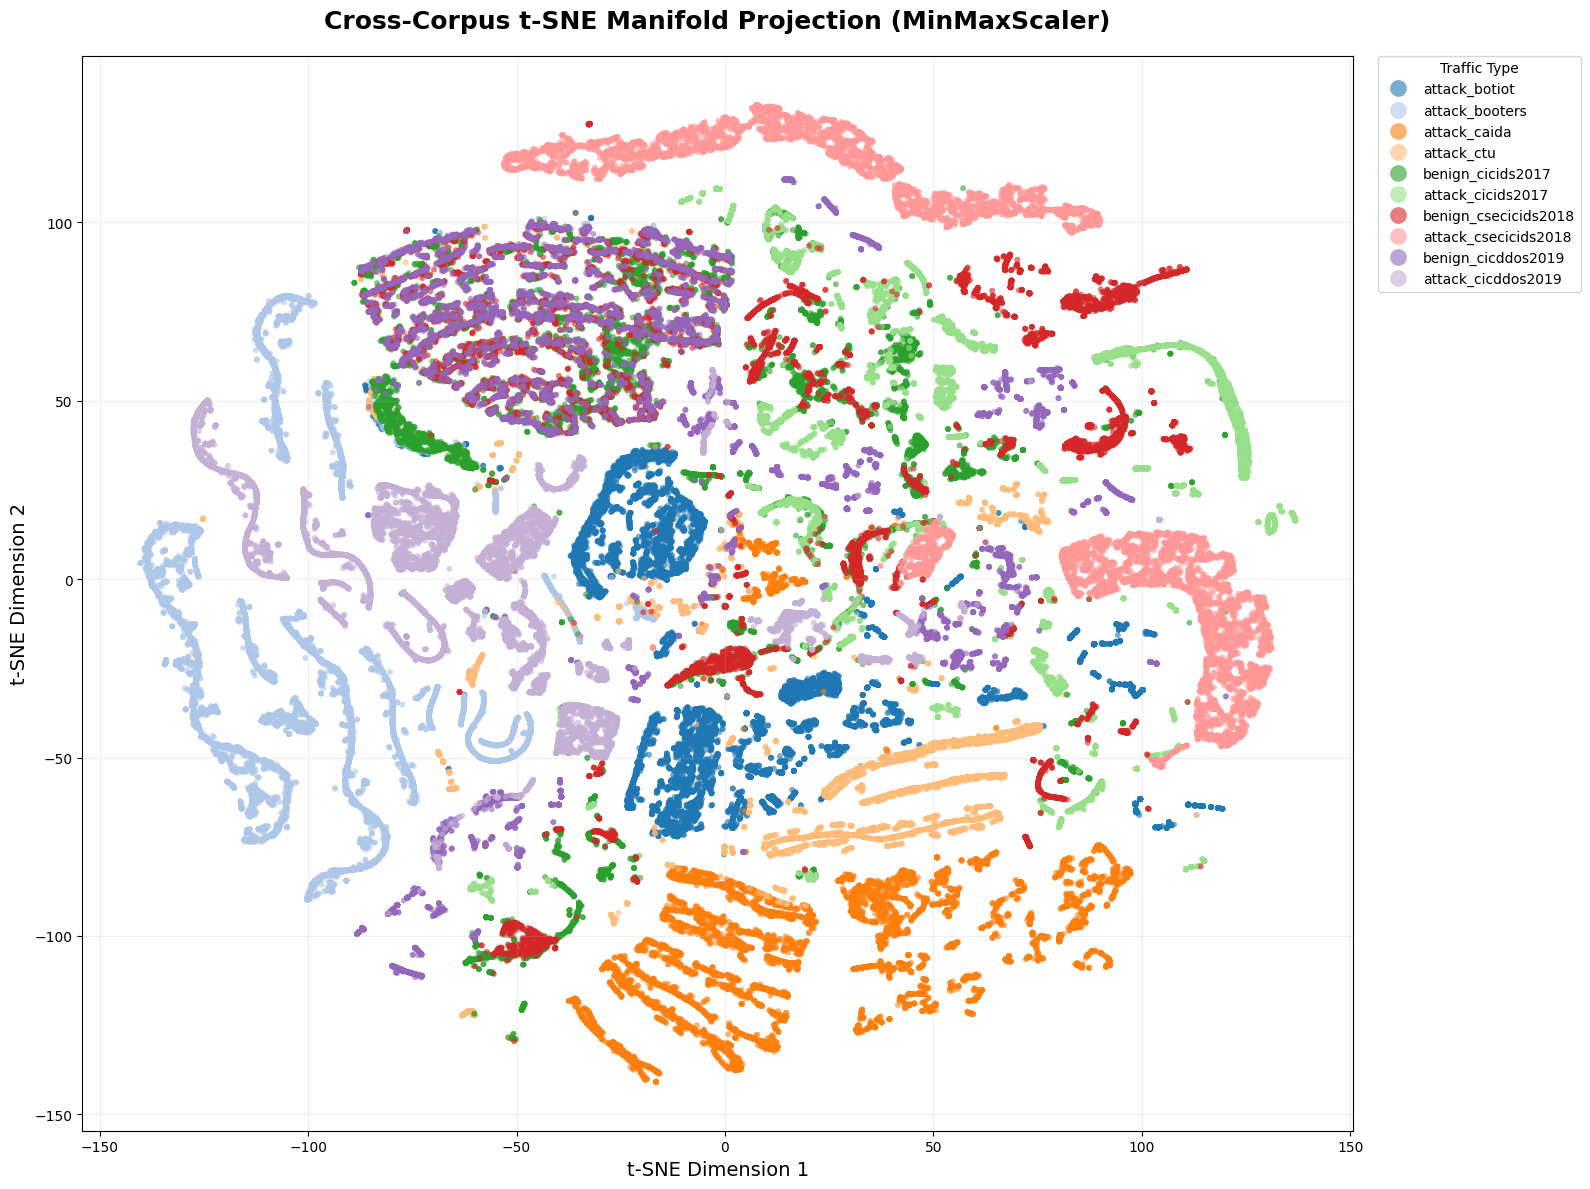

In [4]:
import time
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import MinMaxScaler

# --- 1. FEATURE SCALING (MinMax) ---
# We are shrinking all features to fit strictly between 0.0 and 1.0
print("Applying MinMaxScaler to 79 features...")
minmax_scaler = MinMaxScaler()
X_scaled_minmax = minmax_scaler.fit_transform(X)
print("Scaling complete.")

# --- 2. T-SNE EXECUTION ---
print("\nInitializing t-SNE Engine for MinMax data...")
start_time = time.time()

# Using the exact same hyperparameters to ensure a fair comparison
tsne_engine_minmax = TSNE(
    n_components=2, 
    perplexity=50,       
    max_iter=1000,       
    n_jobs=-1,           # Utilizing all 64 Xeon threads
    random_state=42, 
    verbose=1            
)

print("\nStarting dimensionality reduction. Watch the console...")
X_tsne_minmax = tsne_engine_minmax.fit_transform(X_scaled_minmax)

elapsed_time = (time.time() - start_time) / 60
print(f"\nSUCCESS: MinMax t-SNE completed in {elapsed_time:.2f} minutes.")

# --- 3. HIGH-RESOLUTION VISUALIZATION ---
print("\nGenerating cluster visualization...")
OUTPUT_IMAGE_MINMAX = "Cross_Corpus_tSNE_MinMax.png"

# Package the new coordinates with your original labels
df_tsne_minmax = pd.DataFrame({
    'TSNE_Dimension_1': X_tsne_minmax[:, 0],
    'TSNE_Dimension_2': X_tsne_minmax[:, 1],
    'Dataset_Label': y.values
})

# Create the canvas
plt.figure(figsize=(16, 12))

sns.scatterplot(
    data=df_tsne_minmax,
    x='TSNE_Dimension_1',
    y='TSNE_Dimension_2',
    hue='Dataset_Label',
    palette='tab20',
    alpha=0.6,
    s=15,
    edgecolor=None
)

# Professional Aesthetics
plt.title("Cross-Corpus t-SNE Manifold Projection (MinMaxScaler)", fontsize=18, fontweight='bold', pad=20)
plt.xlabel("t-SNE Dimension 1", fontsize=14)
plt.ylabel("t-SNE Dimension 2", fontsize=14)

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., markerscale=3, title="Traffic Type")
plt.grid(alpha=0.2)
plt.tight_layout()

# Save the new image
plt.savefig(OUTPUT_IMAGE_MINMAX, dpi=300, bbox_inches='tight')
print(f"Visualization saved successfully to '{OUTPUT_IMAGE_MINMAX}'.")

plt.show()